#### Question 1 - Gradient Descent 

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d

In [10]:
# Get the x and f(x)
x_data = np.array([0.8, 0.9, 1.0, 1.1, 1.2, 1.3, 1.4, 1.5, 1.6])
f_data = np.array([-1.784, -1.952, -2.080, -2.168, -2.216, -2.224, -2.192, -2.120, -2.008])

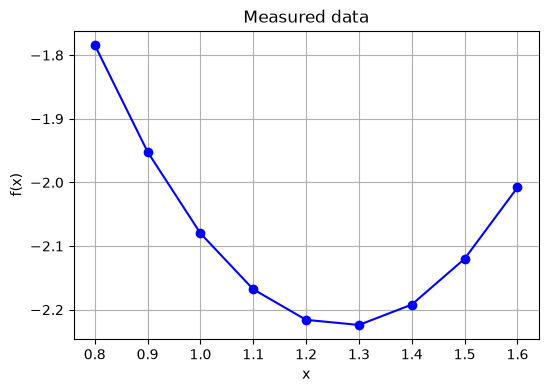

In [11]:
# (a) Plot the data

plt.figure(figsize=(6, 4))
plt.plot(x_data, f_data, 'bo-')
plt.xlabel('x'); plt.ylabel('f(x)'); plt.title('Measured data'); plt.grid(True)
plt.show()


In [12]:
# ---- Numerical derivative from the measured data ----
# Central differences on the grid (forward/backward at the ends), then
# interpolate (and extrapolate if needed) to evaluate at any x.
df_data = np.gradient(f_data, x_data)
f_interp  = interp1d(x_data, f_data,  kind='linear', fill_value='extrapolate')
df_interp = interp1d(x_data, df_data, kind='linear', fill_value='extrapolate')

In [13]:
# ---- Gradient descent ----
def gradient_descent(x0, lr, n_iter=7):
    rows, x = [], x0
    for k in range(1, n_iter + 1):
        d = float(df_interp(x))
        rows.append({'k': k, 'x(k)': x, "f'(x(k))": d, 'f(x(k))': float(f_interp(x))})
        x = x - lr * d          # update step
    return pd.DataFrame(rows)


 k   x(k)  f'(x(k))  f(x(k))
 1 0.9000   -1.4800  -1.9520
 2 1.0480   -0.8880  -2.1222
 3 1.1368   -0.5328  -2.1857
 4 1.1901   -0.3197  -2.2112
 5 1.2220   -0.1918  -2.2178
 6 1.2412   -0.1151  -2.2193
 7 1.2527   -0.0691  -2.2202


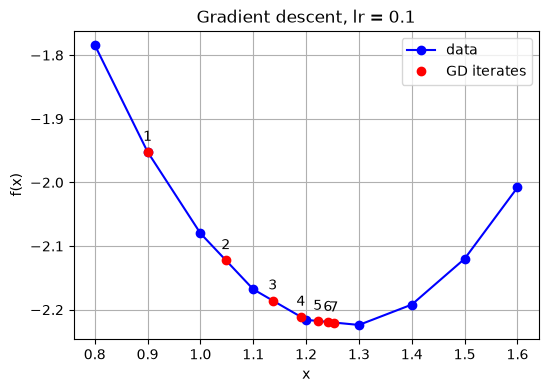

 k   x(k)  f'(x(k))  f(x(k))
 1 0.9000   -1.4800  -1.9520
 2 1.6400    1.2000  -1.9632
 3 1.0400   -0.9200  -2.1152
 4 1.5000    0.9200  -2.1200
 5 1.0400   -0.9200  -2.1152
 6 1.5000    0.9200  -2.1200
 7 1.0400   -0.9200  -2.1152


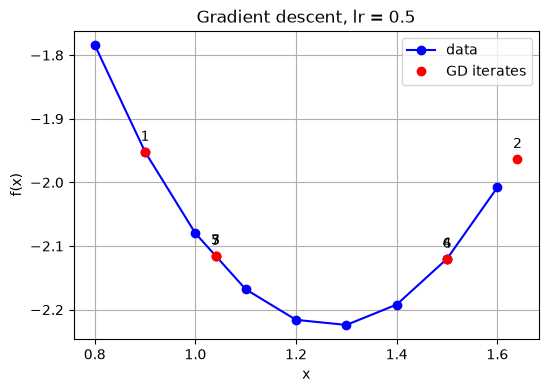

In [14]:

def plot_run(table, lr):
    xs = np.linspace(0.8, 1.65, 200)
    plt.figure(figsize=(6, 4))
    plt.plot(x_data, f_data, 'bo-', label='data')
    plt.plot(table['x(k)'], table['f(x(k))'], 'ro', label='GD iterates')
    for _, r in table.iterrows():
        plt.annotate(int(r['k']), (r['x(k)'], r['f(x(k))']),
                     textcoords='offset points', xytext=(0, 8), ha='center')
    plt.xlabel('x'); plt.ylabel('f(x)'); plt.title(f'Gradient descent, lr = {lr}')
    plt.legend(); plt.grid(True); plt.show()

# (b, c, d.i, d.ii) learning rate 0.1, start at x = 0.9
t1 = gradient_descent(0.9, lr=0.1, n_iter=7)
print(t1.to_string(index=False, float_format=lambda v: f'{v:.4f}'))
plot_run(t1, 0.1)

# (d.iii) learning rate 0.5
t2 = gradient_descent(0.9, lr=0.5, n_iter=7)
print(t2.to_string(index=False, float_format=lambda v: f'{v:.4f}'))
plot_run(t2, 0.5)